# 1. Wprowadzenie

**Arkadiusz Liber** · *Falki w praktyce. Od wzoru do kodu*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/blob/main/rozdzial-01.ipynb)

Notatnik do książki. Zawiera wszystkie programy z tekstu rozdziału oraz ćwiczenia z rozwiązaniami.

Notatnik działa lokalnie (Jupyter) i w Google Colab. Komórki można uruchamiać po kolei poleceniem *Uruchom wszystko*.

In [1]:
# Uruchom tę komórkę jako pierwszą (lokalnie albo w Google Colab).
import sys, subprocess, importlib.util, os
if importlib.util.find_spec("pywt") is None:      # PyWavelets
    subprocess.check_call([sys.executable, "-m", "pip",
                           "install", "-q", "PyWavelets"])
import numpy as np
import matplotlib.pyplot as plt
import pywt

SZARY, NIEBIESKI, RDZAWY, ZIELONY = "#757575", "#1273E2", "#D93B0B", "#078832"
FIOLET, BURSZTYN = "#9258D5", "#B36000"
plt.rcParams.update({
    "text.color": SZARY, "axes.labelcolor": SZARY, "axes.edgecolor": SZARY,
    "xtick.color": SZARY, "ytick.color": SZARY, "axes.titlecolor": SZARY,
    "font.size": 10, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False})


## Programy z tekstu rozdziału

### Kod 1.1. Widmo i skalogram sygnału z ilustracji 1.2 (Python, biblioteka PyWavelets)

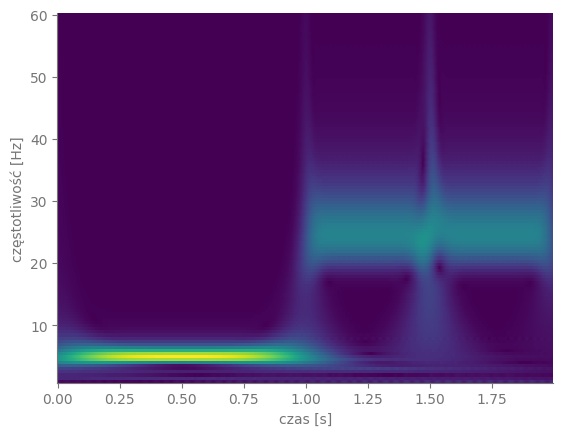

In [2]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

# częstotliwość próbkowania [Hz]
fs = 500
t = np.arange(0, 2, 1/fs)
s = np.where(t < 1,
             np.sin(2*np.pi*5*t),
             np.sin(2*np.pi*25*t))
# krótki impuls w chwili t = 1,5 s
s += 2.0*np.exp(-((t - 1.5)/0.008)**2)

# widmo amplitudowe
widmo = np.abs(np.fft.rfft(s))
f = np.fft.rfftfreq(len(s), 1/fs)

# skalogram: falka Morleta, 1–60 Hz
falka = "cmor1.5-1.0"
czest = np.linspace(1, 60, 120)
skale = pywt.frequency2scale(falka, czest/fs)
wsp, fr = pywt.cwt(s, skale, falka,
                   sampling_period=1/fs)

plt.pcolormesh(t, fr, np.abs(wsp))
plt.xlabel("czas [s]")
plt.ylabel("częstotliwość [Hz]")
plt.show()

## Ćwiczenia i rozwiązania

### Ćwiczenie 1.1
Wyznacz wielomian interpolacyjny Lagrange'a dla punktów (−1, 2), (0, 1), (1, 2), (2, 5). Jakiego stopnia jest otrzymany wielomian i dlaczego jest niższy od 3?

### Rozwiązanie 1.1

In [3]:
x = np.array([-1., 0, 1, 2]); y = np.array([2., 1, 2, 5])
wsp = np.polyfit(x, y, 3)            # wielomian stopnia <= 3 przez 4 punkty
print(np.round(wsp, 10))             # [0. 1. 0. 1.]  ->  W(x) = x^2 + 1
# Współczynnik przy x^3 jest zerem: wszystkie cztery punkty leżą na paraboli.

[-0.  1.  0.  1.]


### Ćwiczenie 1.2
Metodą najmniejszych kwadratów wyznacz prostą aproksymującą punkty (0, 1), (1, 3), (2, 4), (3, 4).

### Rozwiązanie 1.2

In [4]:
x = np.array([0., 1, 2, 3]); Y = np.array([1., 3, 4, 4])
X = np.c_[x, np.ones(4)]
A = np.linalg.solve(X.T @ X, X.T @ Y)   # równania normalne (1.10)
print(A)                                # [1.  1.5]  ->  f(x) = x + 1,5

[1.  1.5]


### Ćwiczenie 1.3
Dla wyniku z ćwiczenia 1.2 oblicz wektor odchyleń i sprawdź, że jest prostopadły do obu kolumn macierzy **X**.

### Rozwiązanie 1.3

In [5]:
r = Y - X @ A
print(r)                 # [-0.5  0.5  0.5 -0.5]
print(X.T @ r)           # [0. 0.]

[-0.5  0.5  0.5 -0.5]
[-4.44089210e-16 -1.11022302e-15]


### Ćwiczenie 1.4
Powtórz obliczenia z ilustracji 1.4, zastępując węzły równoodległe węzłami Czebyszewa. Porównaj maksymalny błąd interpolacji dla *n* = 10.

### Rozwiązanie 1.4

węzły równoodległe: błąd maksymalny 1.916
węzły Czebyszewa: błąd maksymalny 0.109


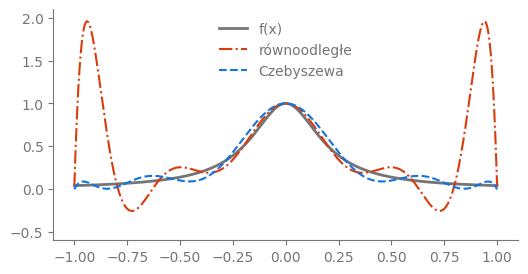

In [6]:
f = lambda x: 1/(1 + 25*x**2)
n = 10
xx = np.linspace(-1, 1, 2001)
wezly = {"równoodległe": np.linspace(-1, 1, n + 1),
         "Czebyszewa": np.cos((2*np.arange(n + 1) + 1)*np.pi/(2*(n + 1)))}
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(xx, f(xx), color=SZARY, lw=2, label="f(x)")
for (nazwa, xk), kolor, styl in zip(wezly.items(), (RDZAWY, NIEBIESKI), ("-.", "--")):
    p = np.polyfit(xk, f(xk), n)
    blad = np.max(np.abs(np.polyval(p, xx) - f(xx)))
    print(f"węzły {nazwa}: błąd maksymalny {blad:.3f}")
    ax.plot(xx, np.polyval(p, xx), color=kolor, ls=styl, label=nazwa)
ax.set_ylim(-0.6, 2.1); ax.legend(frameon=False); plt.show()

### Ćwiczenie 1.5
Oblicz sumy częściowe szeregu (1.7) dla 4, 16 i 64 składników. Jak zmienia się wysokość przerzutu w pobliżu skoku, a jak jego szerokość?

### Rozwiązanie 1.5

In [7]:
x = np.linspace(-np.pi, np.pi, 200001)
for m in (4, 16, 64):
    k = 2*np.arange(m) + 1
    g = sum(4/(np.pi*kk)*np.sin(kk*x) for kk in k)
    i = np.argmax(g)
    print(f"{m:3d} składników: maksimum {g[i]:.4f} "
          f"(przerzut {100*(g[i]-1)/2:.2f}% skoku), w odległości {abs(x[i]):.4f} od skoku")
# Wysokość przerzutu pozostaje bliska 9% wartości skoku, a jego szerokość maleje.

  4 składników: maksimum 1.1842 (przerzut 9.21% skoku), w odległości 2.7489 od skoku
 16 składników: maksimum 1.1793 (przerzut 8.97% skoku), w odległości 3.0434 od skoku
 64 składników: maksimum 1.1790 (przerzut 8.95% skoku), w odległości 0.0245 od skoku


### Ćwiczenie 1.6
W kodzie z punktu 1.2 przesuń impuls do chwili *t* = 0,5 s i zamień kolejność sinusoid. Jak zmieni się widmo amplitudowe, a jak skalogram?

### Rozwiązanie 1.6

największa względna różnica widm amplitudowych: 0.0


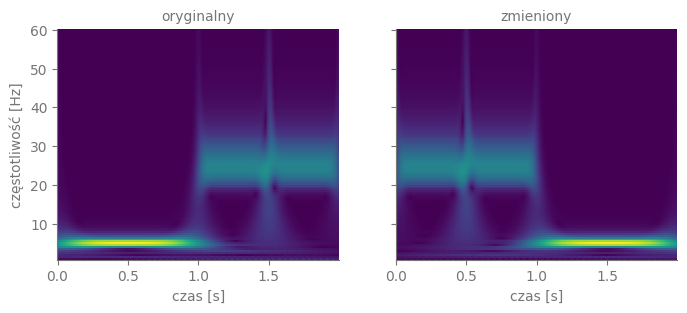

In [8]:
fs = 500
t = np.arange(0, 2, 1/fs)
def sygnal(f1, f2, t_imp):
    s = np.where(t < 1, np.sin(2*np.pi*f1*t), np.sin(2*np.pi*f2*t))
    return s + 2.0*np.exp(-((t - t_imp)/0.008)**2)
a, b = sygnal(5, 25, 1.5), sygnal(25, 5, 0.5)
wa, wb = np.abs(np.fft.rfft(a)), np.abs(np.fft.rfft(b))
print("największa względna różnica widm amplitudowych:",
      round(float(np.max(np.abs(wa - wb))/wa.max()), 3))
falka = "cmor1.5-1.0"
czest = np.linspace(1, 60, 120)
skale = pywt.frequency2scale(falka, czest/fs)
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
for ax, s, tyt in zip(axs, (a, b), ("oryginalny", "zmieniony")):
    wsp, fr = pywt.cwt(s, skale, falka, sampling_period=1/fs)
    ax.pcolormesh(t, fr, np.abs(wsp)); ax.set_title(tyt); ax.set_xlabel("czas [s]")
axs[0].set_ylabel("częstotliwość [Hz]"); plt.show()
# Widma amplitudowe są prawie takie same, a skalogramy wyraźnie różne.